# Spatial Analysis Concepts — from Alteryx to Python

**Brown Belt I · Class 19 · Spatial Tools**

In class we used Alteryx Designer's spatial tools. This notebook walks through the **same ideas in Python**, one concept at a time, on a tiny made-up dataset: 3 coffee shops and 8 customers in Chicago.

Each section has:
1. a short explanation in plain language, with the **matching Alteryx tool**;
2. a small piece of Python you can run and change.

You don't need to be a Python expert. Run each cell from top to bottom (**Shift + Enter**) and read the comments.

**Setup** (run once in a terminal, ideally inside a virtual environment):

```
pip install geopandas shapely pyproj matplotlib folium jupyter
```

| Python library | What it does here |
|---|---|
| `pandas` | tables (like an Alteryx data stream) |
| `shapely` | single shapes: points, polygons, distances |
| `geopandas` | tables with a geometry column (a "spatial" data stream) |
| `pyproj` | coordinate systems (used inside geopandas) |
| `matplotlib`, `folium` | static and interactive maps (like the Browse tool) |

In [1]:
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, Polygon, box
import matplotlib.pyplot as plt
import folium

print("geopandas", gpd.__version__, "| shapely", shapely.__version__)

geopandas 1.2.0 | shapely 2.2.0


## 1. What is spatial analysis?

Spatial analysis treats **location as data**: something you can calculate with, compare and join to other business data, not just a dot on a map. Typical questions:

- *Site selection:* is a new store close to customers, roads and suppliers?
- *Logistics:* which warehouse is nearest to each delivery?
- *Territories:* which sales region does each customer belong to?

A spatial workflow usually follows five steps:

1. **Prepare the location data** — clean addresses or lat/long values.
2. **Represent the features** — a store becomes a **point**, a sales territory becomes a **polygon** (an area).
3. **Choose the relationship** — distance, nearest, inside/outside, trade area.
4. **Calculate new attributes** — append a distance, a nearest-store ID, a territory name to each row.
5. **Combine with business data** — use those new columns with revenue, demand and so on.

The rest of this notebook follows those steps.

## 2. Create Points — turning numbers into points

**Alteryx tool: Create Points.** The first and most important spatial tool: every other spatial tool needs spatial objects, and Create Points turns two numeric columns (latitude and longitude) into a point.

Create Points accepts coordinates in three forms:

| Form | Example |
|---|---|
| Lat/long as floating point | 23.4567 latitude, 78.912 longitude |
| Lat/long as integers (× 1,000,000) | 23,456,700 latitude, 78,912,000 longitude |
| Projected floating point | x/y values in a projection (e.g. metres) |

Below, the **stores** use ordinary decimal lat/long, and the **customers** arrive as integers × 1,000,000, so we divide by 1,000,000 first.

> ⚠️ Watch the order: a point is **(x, y) = (longitude, latitude)**. Mixing them up is the most common beginner mistake.

In [2]:
# Our stores: plain decimal latitude / longitude
stores = pd.DataFrame({
    "store":     ["A - Loop", "B - Lincoln Park", "C - Hyde Park"],
    "latitude":  [41.8837, 41.9214, 41.7943],
    "longitude": [-87.6278, -87.6513, -87.5907],
})

# Our customers: coordinates stored as integers x 1,000,000, plus yearly spend in $
customers = pd.DataFrame({
    "customer": [1, 2, 3, 4, 5, 6, 7, 8],
    "lat_int":  [41890200, 41910000, 41930000, 41868000, 41800000, 41780000, 41850000, 41960000],
    "lon_int":  [-87624300, -87640000, -87660000, -87650000, -87600000, -87580000, -87620000, -87700000],
    "spend":    [420, 310, 150, 275, 500, 90, 360, 60],
})

# Integer -> decimal degrees
customers["latitude"] = customers["lat_int"] / 1_000_000
customers["longitude"] = customers["lon_int"] / 1_000_000

# "Create Points": build a geometry column from x = longitude, y = latitude.
# EPSG:4326 means "ordinary GPS latitude/longitude in degrees" (more in section 3).
stores_gdf = gpd.GeoDataFrame(
    stores, geometry=gpd.points_from_xy(stores.longitude, stores.latitude), crs="EPSG:4326")
customers_gdf = gpd.GeoDataFrame(
    customers, geometry=gpd.points_from_xy(customers.longitude, customers.latitude), crs="EPSG:4326")

stores_gdf

,store,latitude,longitude,geometry
0,A - Loop,41.8837,-87.6278,POINT (-87.6278 41.8837)
1,B - Lincoln Park,41.9214,-87.6513,POINT (-87.6513 41.9214)
2,C - Hyde Park,41.7943,-87.5907,POINT (-87.5907 41.7943)


### Points *and* polygons

A point marks *one place*. A **polygon** marks an *area*: a territory, a ZIP code, a trade area. Here we draw two made-up sales territories, North and South, as rectangles.

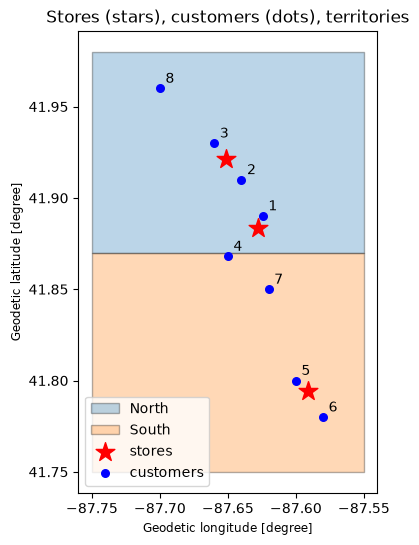

In [3]:
# A polygon is a list of (longitude, latitude) corners
north = Polygon([(-87.75, 41.87), (-87.55, 41.87), (-87.55, 41.98), (-87.75, 41.98)])
south = Polygon([(-87.75, 41.75), (-87.55, 41.75), (-87.55, 41.87), (-87.75, 41.87)])

territories_gdf = gpd.GeoDataFrame(
    {"territory": ["North", "South"]}, geometry=[north, south], crs="EPSG:4326")

ax = territories_gdf.plot(column="territory", alpha=0.3, edgecolor="black", legend=True, figsize=(5, 6))
stores_gdf.plot(ax=ax, color="red", marker="*", markersize=200, label="stores")
customers_gdf.plot(ax=ax, color="blue", markersize=30, label="customers")
for _, c in customers_gdf.iterrows():
    ax.annotate(c.customer, (c.longitude, c.latitude), xytext=(4, 4), textcoords="offset points")
ax.set_title("Stores (stars), customers (dots), territories")
ax.legend(loc="lower left")
plt.show()

## 3. Coordinate systems — degrees vs. metres

Latitude/longitude are **angles on a globe**, measured in degrees. One degree of longitude is not a fixed distance (it shrinks as you move away from the equator), so you can't measure distance in degrees.

A **projected** coordinate system flattens a region of the Earth onto a grid in **metres**. That's the "projected floating point" option in Create Points.

Each coordinate system has a code (an **EPSG** code):
- `EPSG:4326`: GPS latitude/longitude (degrees). Good for storing and for web maps.
- `EPSG:26916`: UTM zone 16N (metres). Accurate for the Chicago area, good for distances and areas.

Alteryx handles this for you behind the scenes. In Python you choose it with `.to_crs()`.

> ⚠️ A common real-world problem: two files in **different** coordinate systems won't line up. Always check `.crs` before combining layers.

In [4]:
METRIC_CRS = "EPSG:26916"   # UTM zone 16N, units = metres

stores_m      = stores_gdf.to_crs(METRIC_CRS)
customers_m   = customers_gdf.to_crs(METRIC_CRS)
territories_m = territories_gdf.to_crs(METRIC_CRS)

print("Store A in degrees:", stores_gdf.geometry[0])
print("Store A in metres: ", stores_m.geometry[0])
print("CRS of customers_m:", customers_m.crs.name)

Store A in degrees: POINT (-87.6278 41.8837)
Store A in metres:  POINT (447912.41701934894 4637054.220807607)
CRS of customers_m: NAD83 / UTM zone 16N


## 4. Distance — how far apart are two things?

**Alteryx tool: Distance.** Calculates the distance between two spatial objects:

- **point → point** (customer to store)
- **point → edge** of a line or polygon (customer to the territory border)

In Alteryx the first input must be a point and the second can be a point or a polygon. You choose the **units** (miles, km, metres, feet), and Alteryx can also give **drive time**.

In Python, once the data is in a metric coordinate system, `.distance()` returns metres, and we convert to km or miles.

> **Straight line vs. drive time.** `.distance()` is "as the crow flies". Real travel along roads can tell a very different story. Drive time needs a road network (Alteryx uses its own street data; in Python you'd use a routing tool such as OSMnx), which is beyond this notebook.

In [5]:
store_a = stores_m.geometry[0]   # Store A - Loop

dist = customers_m[["customer"]].copy()
dist["km_to_A"]    = (customers_m.distance(store_a) / 1000).round(2)
dist["miles_to_A"] = (customers_m.distance(store_a) / 1609.344).round(2)
dist

,customer,km_to_A,miles_to_A
0,1,0.78,0.48
1,2,3.09,1.92
2,3,5.79,3.60
3,4,2.54,1.58
4,5,9.58,5.95
5,6,12.18,7.57
6,7,3.80,2.36
7,8,10.37,6.45


**Point → polygon.** In Alteryx's Distance tool you also choose what happens when the point is *inside* the polygon. Python shows both options:
- distance to the **polygon**: 0 if the point is inside;
- distance to the polygon's **edge** (its *boundary*): how far to the border, even from inside.

In [6]:
north_m = territories_m.geometry[0]

edge = customers_m[["customer"]].copy()
edge["km_to_North_area"] = (customers_m.distance(north_m) / 1000).round(2)
edge["km_to_North_edge"] = (customers_m.distance(north_m.boundary) / 1000).round(2)
edge

,customer,km_to_North_area,km_to_North_edge
0,1,0.00,2.24
1,2,0.00,4.44
2,3,0.00,5.56
3,4,0.23,0.23
4,5,7.78,7.78
5,6,10.00,10.00
6,7,2.22,2.22
7,8,0.00,2.22


## 5. Find Nearest — which store is closest?

**Alteryx tool: Find Nearest.** For each **target** point it finds the closest objects in a **universe**. You set:
- **how many** nearest objects to find (1, 2, 3 …),
- a **maximum distance** to search,
- the units, and which columns to keep in the output.

Useful when you have thousands of locations: nearest warehouse for each delivery, closest store for each customer, ranking locations by distance.

Here: target = customers, universe = stores.

In [7]:
# Nearest single store for each customer, searching at most 5 km (5,000 m)
nearest = gpd.sjoin_nearest(
    customers_m[["customer", "spend", "geometry"]],
    stores_m[["store", "geometry"]],
    how="left",
    max_distance=5_000,
    distance_col="distance_m",
)
nearest["distance_km"] = (nearest["distance_m"] / 1000).round(2)
nearest[["customer", "store", "distance_km"]]

,customer,store,distance_km
0,1,A - Loop,0.78
1,2,B - Lincoln Park,1.57
2,3,B - Lincoln Park,1.20
3,4,A - Loop,2.54
4,5,C - Hyde Park,1.00
5,6,C - Hyde Park,1.82
6,7,A - Loop,3.80
7,8,NaN,NaN


Customer 8 has no store within 5 km, so `store` is empty, just as Find Nearest returns nothing beyond the maximum distance.

**Finding the 2 nearest stores** (like setting "number of points to find" = 2): pair every customer with every store, measure, sort, and keep the top 2.

In [8]:
pairs = customers_m[["customer", "geometry"]].merge(
    stores_m[["store", "geometry"]], how="cross", suffixes=("_cust", "_store"))
pairs["distance_km"] = (
    gpd.GeoSeries(pairs.geometry_cust).distance(gpd.GeoSeries(pairs.geometry_store)) / 1000
).round(2)

top2 = (pairs.sort_values(["customer", "distance_km"])
             .groupby("customer").head(2)
             .assign(rank=lambda d: d.groupby("customer").cumcount() + 1))
top2[["customer", "rank", "store", "distance_km"]]

,customer,rank,store,distance_km
0,1,1,A - Loop,0.78
1,1,2,B - Lincoln Park,4.12
4,2,1,B - Lincoln Park,1.57
3,2,2,A - Loop,3.09
7,3,1,B - Lincoln Park,1.20
6,3,2,A - Loop,5.79
9,4,1,A - Loop,2.54
10,4,2,B - Lincoln Park,5.93
14,5,1,C - Hyde Park,1.00
12,5,2,A - Loop,9.58


## 6. Trade Area — an area around a point

**Alteryx tool: Trade Area.** Draws a **polygon around a point**, for example "everything within 3 km of the store". The size can be:
- a **radius** (distance), or
- a **drive time** (needs road data, chosen from a field).

With radius trade areas you can tick **Eliminate Overlap**: where two trade areas overlap, the shared part is split between the stores so each customer belongs to only one.

In Python, a radius trade area is a **buffer**: `point.buffer(3000)` is a circle of 3,000 m. To remove overlaps we cut each circle with a **Voronoi cell**: the region of the map that is closer to that store than to any other.

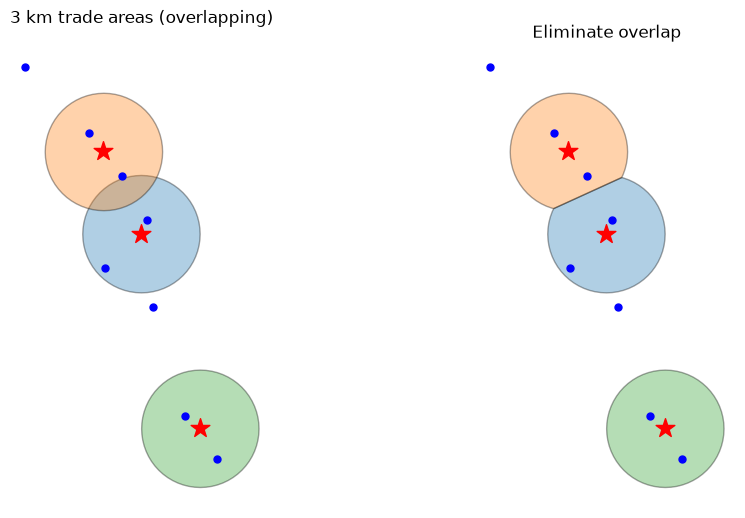

In [9]:
RADIUS_M = 3_000   # 3 km trade areas

trade_areas = stores_m[["store", "geometry"]].copy()
trade_areas["geometry"] = stores_m.buffer(RADIUS_M)

# Eliminate overlap: keep only the part of each circle that is closer to its own store
cells = shapely.voronoi_polygons(
    shapely.MultiPoint(list(stores_m.geometry)), extend_to=trade_areas.union_all().envelope).geoms
trade_areas_no_overlap = trade_areas.copy()
trade_areas_no_overlap["geometry"] = [
    circle.intersection(next(c for c in cells if c.contains(pt)))
    for circle, pt in zip(trade_areas.geometry, stores_m.geometry)
]

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, ta, title in [(axes[0], trade_areas, "3 km trade areas (overlapping)"),
                      (axes[1], trade_areas_no_overlap, "Eliminate overlap")]:
    ta.plot(ax=ax, column="store", alpha=0.35, edgecolor="black")
    stores_m.plot(ax=ax, color="red", marker="*", markersize=200)
    customers_m.plot(ax=ax, color="blue", markersize=25)
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## 7. Spatial Match — inside, touching, overlapping

**Alteryx tool: Spatial Match.** The most versatile spatial tool. It matches records from a **target** to a **universe** based on how their shapes relate, using one of **six actions**:

| Alteryx action | Meaning | Python (shapely) |
|---|---|---|
| **Intersects** | the two shapes have some area in common | `a.intersects(b) and not a.touches(b)` |
| **Contains** | target contains the universe object entirely | `a.contains(b)` |
| **Within** | target is entirely inside the universe object | `a.within(b)` |
| **Touches** | they touch at the boundary but share no interior | `a.touches(b)` |
| **Touches or Intersects** | they share interior space *or* touch the boundary | `a.intersects(b)` |
| **Bounding Rectangle Overlaps** | the rectangles drawn around each shape overlap | `a.envelope.intersects(b.envelope)` |

Note: in shapely, `intersects` already counts touching, so the Alteryx-style "Intersects" excludes pure touches.

### Example 1: which territory is each customer in? (*Within*)
This is **data enrichment**: we get a reliable territory column from coordinates instead of messy text fields.

In [10]:
cust_territory = gpd.sjoin(
    customers_m[["customer", "spend", "geometry"]],
    territories_m,
    how="left",
    predicate="within",       # target (customer) is within universe (territory)
)
cust_territory[["customer", "territory"]]

,customer,territory
0,1,North
1,2,North
2,3,North
3,4,South
4,5,South
5,6,South
6,7,South
7,8,North


### Example 2: which customers fall inside each trade area? (*Contains*)
Here the target is the trade area polygon and the universe is the customers.

In [11]:
in_trade_area = gpd.sjoin(
    trade_areas_no_overlap, customers_m[["customer", "spend", "geometry"]], predicate="contains")
in_trade_area.groupby("store")["customer"].apply(list)

store
A - Loop            [4, 1]
B - Lincoln Park    [2, 3]
C - Hyde Park       [6, 5]
Name: customer, dtype: object

### Example 3: the six actions on simple shapes
Small squares make it easy to see the differences. Change the coordinates and re-run to experiment.

In [12]:
big       = box(0, 0, 4, 4)
pairs_demo = {
    "small square inside big": (big, box(1, 1, 2, 2)),
    "squares side by side":    (box(0, 0, 2, 2), box(2, 0, 4, 2)),
    "squares overlapping":     (box(0, 0, 2, 2), box(1, 1, 3, 3)),
    "L-shape vs. far square":  (Polygon([(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)]), box(2, 2, 2.8, 2.8)),
}

def six_actions(a, b):
    return {
        "Intersects":            a.intersects(b) and not a.touches(b),
        "Contains":              a.contains(b),
        "Within":                a.within(b),
        "Touches":               a.touches(b),
        "Touches or Intersects": a.intersects(b),
        "Bounding Rect Overlaps": a.envelope.intersects(b.envelope),
    }

pd.DataFrame({name: six_actions(a, b) for name, (a, b) in pairs_demo.items()}).T

,Intersects,Contains,Within,Touches,Touches or Intersects,Bounding Rect Overlaps
small square inside big,True,True,False,False,True,True
squares side by side,False,False,False,True,True,True
squares overlapping,True,False,False,False,True,True
L-shape vs. far square,False,False,False,False,False,True


Look at the last row: the L-shape and the small square **don't touch at all**, yet their *bounding rectangles* overlap. That's why "Bounding Rectangle Overlaps" is fast but rough.

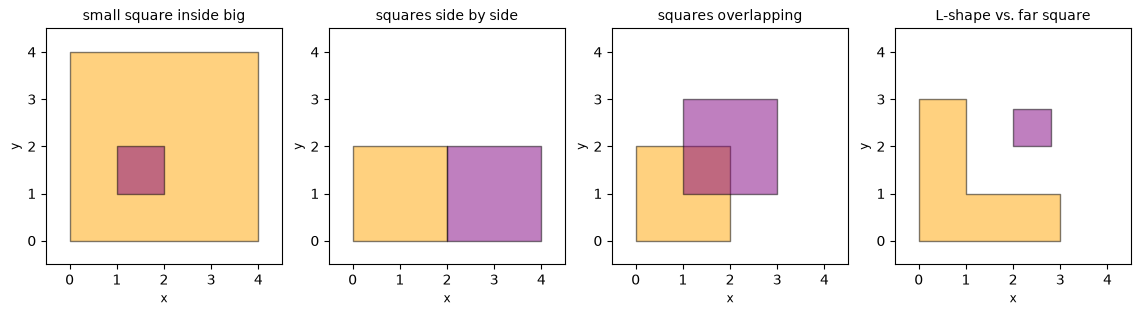

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (name, (a, b)) in zip(axes, pairs_demo.items()):
    gpd.GeoSeries([a]).plot(ax=ax, color="orange", alpha=0.5, edgecolor="black")
    gpd.GeoSeries([b]).plot(ax=ax, color="purple", alpha=0.5, edgecolor="black")
    ax.set_title(name, fontsize=10)
    ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 4.5); ax.set_aspect("equal")
plt.show()

## 8. Map output — looking at the result

**Alteryx tool: Browse** (its map view). In Alteryx you drop a Browse tool after a spatial tool to see the shapes on a map.

In Python, `folium` makes an interactive web map you can zoom and click. Web maps expect latitude/longitude, so we convert back to `EPSG:4326` first.

A map is useful for checking your work, but spatial analysis doesn't *require* one: often the real output is just new columns (a distance, a nearest store, a territory) that feed a report or a model.

In [14]:
m = folium.Map(location=[41.87, -87.63], zoom_start=11)

folium.GeoJson(territories_gdf, name="Territories",
               style_function=lambda f: {"fillOpacity": 0.05, "color": "gray"},
               tooltip=folium.GeoJsonTooltip(["territory"])).add_to(m)
folium.GeoJson(trade_areas_no_overlap.to_crs("EPSG:4326"), name="Trade areas (3 km)",
               tooltip=folium.GeoJsonTooltip(["store"])).add_to(m)

for _, s in stores_gdf.iterrows():
    folium.Marker([s.latitude, s.longitude], tooltip=s.store,
                  icon=folium.Icon(color="red", icon="coffee", prefix="fa")).add_to(m)
for _, c in customers_gdf.iterrows():
    folium.CircleMarker([c.latitude, c.longitude], radius=6, fill=True,
                        tooltip=f"Customer {c.customer}: ${c.spend}").add_to(m)

folium.LayerControl().add_to(m)
m

## 9. Putting it together — spatial + business data

Step 5 of the workflow: the new spatial columns become ordinary columns you can group and sum. Which store "owns" the most customer spend, based on nearest store?

In [15]:
summary = (nearest.groupby("store", dropna=False)
                  .agg(customers=("customer", "count"),
                       total_spend=("spend", "sum"),
                       avg_distance_km=("distance_km", "mean"))
                  .round(2))
summary

,customers,total_spend,avg_distance_km
store,,,
A - Loop,3,1055,2.37
B - Lincoln Park,2,460,1.38
C - Hyde Park,2,590,1.41
NaN,1,60,NaN


The row with an empty store name is customer 8, who has no store within 5 km. That's a possible site for a new store!

## Summary: Alteryx tool → concept → Python

| Alteryx tool | Concept | Python equivalent |
|---|---|---|
| **Create Points** | turn lat/long numbers into point objects | `gpd.points_from_xy(lon, lat)` → `GeoDataFrame(..., crs="EPSG:4326")` |
| *(coordinate settings)* | degrees vs. projected metres | `gdf.to_crs("EPSG:26916")`, check `gdf.crs` |
| **Distance** | point → point or point → polygon edge, in chosen units | `gdf.distance(other)`, `polygon.boundary`, ÷1000 for km, ÷1609.344 for miles |
| **Find Nearest** | closest N objects within a max distance | `gpd.sjoin_nearest(..., max_distance=, distance_col=)`; cross-join + sort for top-N |
| **Trade Area** | polygon around a point (radius), optional eliminate overlap | `gdf.buffer(radius_m)`; Voronoi cells to remove overlap |
| **Spatial Match** | match by intersects / contains / within / touches / touches-or-intersects / bounding box | `gpd.sjoin(..., predicate=...)`, shapely `.within()`, `.contains()`, `.touches()`, `.intersects()`, `.envelope` |
| **Browse** (map) | look at spatial results | `gdf.plot()` (static), `folium.Map` (interactive) |

**Not covered here, but mentioned in the reading:** geocoding (addresses → coordinates), drive-time / road-network distance, and clustering / hotspot analysis.